# Notebook 01 — Dataset Audit and Setup

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Objective:** Inspect the raw dataset, verify file shards and sizes, decode representative TFRecord examples, identify feature dimensions and datatypes, and document the target label and class imbalance.

---
## 1. Project Setup and Environment Verification
We verify Python dependencies and project directory structure before loading the dataset.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

sys.path.append("..")
import src.data_loader as dl

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Setup complete!")

TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 3.0.3
Setup complete!


2. Check Dataset Files

In [2]:
raw_dir = "../data/raw/archive"

for split in ["train", "eval", "test"]:
    files = dl.get_tfrecord_paths(split, raw_dir=raw_dir)
    print(split, ":", len(files), "shards")

train : 15 shards
eval : 2 shards
test : 2 shards


3. Inspect One Data Sample

In [3]:
train_files = dl.get_tfrecord_paths("train", raw_dir=raw_dir)
patch = next(dl.iter_records(train_files, max_records=1))

print("Patch shape:", patch["FireMask"].shape)
print("Available features:", dl.ALL_CHANNELS)

Patch shape: (64, 64)
Available features: ['elevation', 'th', 'vs', 'tmmn', 'tmmx', 'sph', 'pr', 'pdsi', 'NDVI', 'population', 'erc', 'PrevFireMask', 'FireMask']


I0000 00:00:1793081689.820708 1207016 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


4. Check Feature Information

In [4]:
for feature in dl.ALL_CHANNELS:
    data = patch[feature]
    print(feature, "| Shape:", data.shape, "| Type:", data.dtype)

elevation | Shape: (64, 64) | Type: float32
th | Shape: (64, 64) | Type: float32
vs | Shape: (64, 64) | Type: float32
tmmn | Shape: (64, 64) | Type: float32
tmmx | Shape: (64, 64) | Type: float32
sph | Shape: (64, 64) | Type: float32
pr | Shape: (64, 64) | Type: float32
pdsi | Shape: (64, 64) | Type: float32
NDVI | Shape: (64, 64) | Type: float32
population | Shape: (64, 64) | Type: float32
erc | Shape: (64, 64) | Type: float32
PrevFireMask | Shape: (64, 64) | Type: float32
FireMask | Shape: (64, 64) | Type: float32


5. Check Fire Labels

In [5]:
fire = patch["FireMask"]

print("Burned pixels:", np.sum(fire == 1))
print("Unburned pixels:", np.sum(fire == 0))
print("Uncertain pixels:", np.sum(fire == -1))

Burned pixels: 7
Unburned pixels: 4089
Uncertain pixels: 0


6. Visualize Fire Pixel Counts

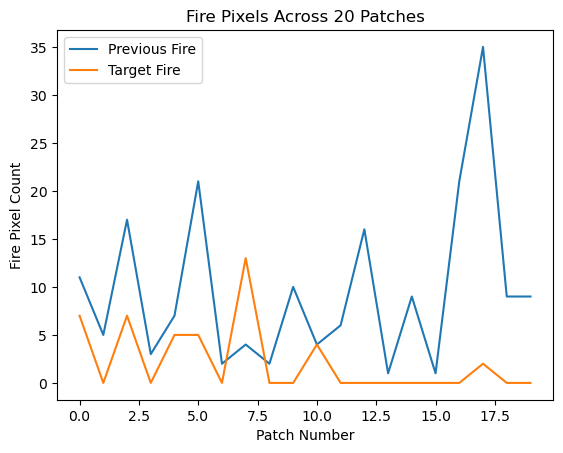

In [6]:
patches = list(dl.iter_records(train_files, max_records=20))

previous_fire = [np.sum(p["PrevFireMask"] == 1) for p in patches]
target_fire = [np.sum(p["FireMask"] == 1) for p in patches]

plt.plot(previous_fire, label="Previous Fire")
plt.plot(target_fire, label="Target Fire")

plt.title("Fire Pixels Across 20 Patches")
plt.xlabel("Patch Number")
plt.ylabel("Fire Pixel Count")
plt.legend()
plt.show()

7. Check Missing Values

In [7]:
for feature in dl.ALL_CHANNELS:
    print(feature, ":", np.isnan(patch[feature]).sum(), "missing values")

elevation : 0 missing values
th : 0 missing values
vs : 0 missing values
tmmn : 0 missing values
tmmx : 0 missing values
sph : 0 missing values
pr : 0 missing values
pdsi : 0 missing values
NDVI : 0 missing values
population : 0 missing values
erc : 0 missing values
PrevFireMask : 0 missing values
FireMask : 0 missing values


The dataset audit confirmed that wildfire data is organized into 64 × 64 spatial patches containing 11 environmental features, a previous fire mask, and a next-day target fire mask. Initial inspection revealed sparse fire pixels, highlighting class imbalance as an important modeling challenge. Feature ranges and missing values should be checked before preprocessing and model training.